<a href="https://colab.research.google.com/github/ryanlin3124/Pytorch-exercises/blob/main/imaging-exercises/basic_imaging_manips/Interpolation_Fourier_Wavelet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The goal of this notebook is to complete these task:
- Image interpolation and reconstruction
- Fourier Transform and low pass filtering
- Wavelet Decomposition and denoising

# 1. Image interpolation and reconstruction
Downsample the image, then try to reconstruct it into original size through:
- nearest neighbors
- bilinear interpolation
- bicubic interpolation



Image size: 1012x901


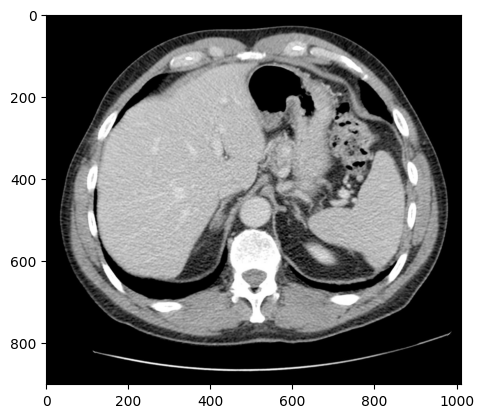

In [26]:
# Import image from Github
from PIL import Image
import requests
import io

url = "https://raw.githubusercontent.com/ryanlin3124/Pytorch-exercises/refs/heads/main/imaging-exercises/abdomenCT_1.png"
response = requests.get(url)

if response.status_code == 200:
    image = Image.open(io.BytesIO(response.content))
else:
    print("Failed to download the image.")
plt.imshow(image)
width, height = image.size
print(f"Image size: {width}x{height}")

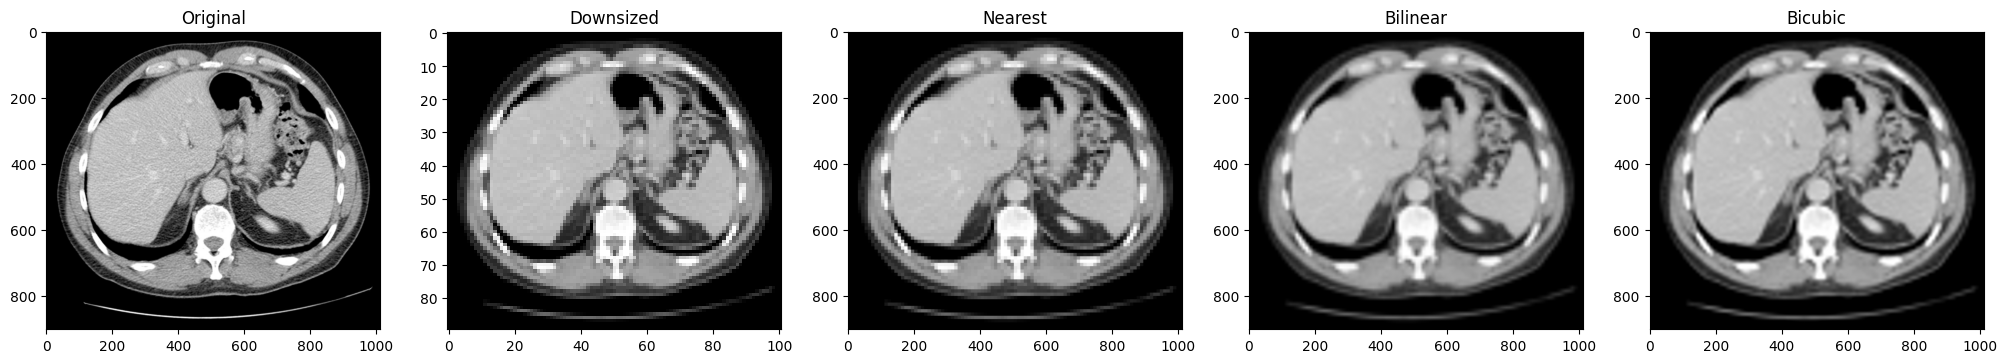

In [25]:
import matplotlib.pyplot as plt
# down size the image using PIL resize
image_downsized = image.resize([101,90])

# upsample the image using Nearest Neighbor
image_upsampled_nearest = image_downsized.resize([width,height], resample=Image.NEAREST)
# umsample via Bilinear
image_upsampled_bilinear = image_downsized.resize([width,height], resample=Image.BILINEAR)
# umsample via Bicubic
image_upsampled_bicubic = image_downsized.resize([width,height], resample=Image.BICUBIC)

# create a 5x1 grid with orig, downsampled, nearest, bilinear, bicubic
fig, ax = plt.subplots(1,5,figsize = (25,5))
ax[0].imshow(image)
ax[0].set_title("Original")
ax[1].imshow(image_downsized)
ax[1].set_title("Downsized")
ax[2].imshow(image_upsampled_nearest)
ax[2].set_title("Nearest")
ax[3].imshow(image_upsampled_bilinear)
ax[3].set_title("Bilinear")
ax[4].imshow(image_upsampled_bicubic)
ax[4].set_title("Bicubic")
plt.show()

 # 2.  Fourier Transform and Low Pass Filters